# Session 10: Making a small model tell the truth

This notebook builds a small next-character model and uses controlled measurements to inspect its training behavior. It is intentionally self-contained so experiments can be repeated without downloading data. The repeated toy corpus makes validation a pipeline check, not evidence of generalization.

The model is a decoder-only Transformer: character and position embeddings, two causal self-attention blocks, and a next-character prediction head. Each training target is the input sequence shifted one character to the right.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(1337)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"PyTorch {torch.__version__}; device: {device}")

PyTorch 2.14.1; device: mps


## Data and character vocabulary

The short, original text below is repeated to make enough next-character windows for a tiny training run. The split is by position in the text; because the corpus repeats, its validation loss must not be interpreted as a generalization result.

In [2]:
passage = """A careful model learns one character at a time. A useful training loop measures the loss, checks the gradients, and updates each weight.
When the input is a short sequence, the target is the same sequence moved one step forward. The model can use the past, but never the future.
Small experiments make hidden details visible. We print tensor shapes, compare a numerical gradient, and keep track of every example in a batch.
A falling loss is a clue, not a proof. We ask what changed, how much computation was used, and whether the measurements support the conclusion.
"""
text = passage * 24
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {char: index for index, char in enumerate(chars)}
itos = {index: char for char, index in stoi.items()}
encode = lambda value: [stoi[char] for char in value]
decode = lambda values: "".join(itos[int(index)] for index in values)

encoded = torch.tensor(encode(text), dtype=torch.long, device=device)
split_at = int(0.9 * len(encoded))
train_data = encoded[:split_at]
val_data = encoded[split_at:]

block_size = 64
batch_size = 32
print(f"Corpus: {len(text):,} characters; vocabulary: {vocab_size} characters")
print(f"Train: {len(train_data):,} characters; validation: {len(val_data):,} characters")

Corpus: 13,632 characters; vocabulary: 32 characters
Train: 12,268 characters; validation: 1,364 characters


## Model

The attention mask is lower triangular: position `t` can attend only to positions `0` through `t`. The residual paths and layer normalization follow a compact pre-norm Transformer block.

In [3]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        if n_embd % n_head != 0:
            raise ValueError("embedding width must be divisible by head count")
        self.n_head = n_head
        self.head_size = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

    def forward(self, x, shape_log=None, prefix="attention"):
        batch, time, channels = x.shape
        qkv_projected = self.qkv(x)
        qkv_heads = qkv_projected.view(
            batch, time, 3, self.n_head, self.head_size
        )
        q, k, v = qkv_heads.unbind(dim=2)
        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        scores = q @ k.transpose(-2, -1) * (self.head_size ** -0.5)
        causal_mask = torch.ones(time, time, dtype=torch.bool, device=x.device).tril()
        scores = scores.masked_fill(~causal_mask, torch.finfo(scores.dtype).min)
        weights = F.softmax(scores, dim=-1)
        attended = weights @ v
        attended_heads = attended
        attended = attended.transpose(1, 2).contiguous().view(batch, time, channels)
        projected = self.proj(attended)
        if shape_log is not None:
            q, k, v = qkv_heads.unbind(dim=2)
            for name, tensor in (
                ("qkv_projected", qkv_projected),
                ("qkv_heads", qkv_heads),
                ("q", q),
                ("k", k),
                ("v", v),
                ("q_heads", q.transpose(1, 2)),
                ("k_heads", k.transpose(1, 2)),
                ("v_heads", v.transpose(1, 2)),
                ("scores", scores),
                ("causal_mask", causal_mask),
                ("weights", weights),
                ("attended_heads", attended_heads),
                ("merged_heads", attended),
                ("projected", projected),
            ):
                shape_log[f"{prefix}.{name}"] = tuple(tensor.shape)
        return projected


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attention = CausalSelfAttention(n_embd, n_head)
        self.ln2 = nn.LayerNorm(n_embd)
        self.feed_forward = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x, shape_log=None, prefix="block"):
        attention_input = self.ln1(x)
        attention_output = self.attention(
            attention_input, shape_log, f"{prefix}.attention"
        )
        attention_residual = x + attention_output
        feed_forward_input = self.ln2(attention_residual)
        expanded = self.feed_forward[0](feed_forward_input)
        activated = self.feed_forward[1](expanded)
        contracted = self.feed_forward[2](activated)
        output = attention_residual + contracted
        if shape_log is not None:
            for name, tensor in (
                ("input", x),
                ("attention_norm", attention_input),
                ("attention_residual", attention_residual),
                ("mlp_norm", feed_forward_input),
                ("mlp_expanded", expanded),
                ("mlp_activated", activated),
                ("mlp_contracted", contracted),
                ("output", output),
            ):
                shape_log[f"{prefix}.{name}"] = tuple(tensor.shape)
        return output


class TinyLanguageModel(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd=64, n_head=4, n_layer=2):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(
            *(TransformerBlock(n_embd, n_head) for _ in range(n_layer))
        )
        self.final_norm = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None, shape_log=None):
        batch, time = idx.shape
        if time > self.block_size:
            raise ValueError(f"sequence length {time} exceeds block size {self.block_size}")
        positions = torch.arange(time, device=idx.device)
        token_embeddings = self.token_embedding(idx)
        position_embeddings = self.position_embedding(positions)
        embedding_sum = token_embeddings + position_embeddings
        x = embedding_sum
        for block_index, block in enumerate(self.blocks):
            x = block(x, shape_log, f"blocks.{block_index}")
        normalized = self.final_norm(x)
        logits = self.lm_head(normalized)
        loss = None
        if targets is not None:
            flattened_logits = logits.reshape(-1, logits.size(-1))
            flattened_targets = targets.reshape(-1)
            loss = F.cross_entropy(flattened_logits, flattened_targets)
        if shape_log is not None:
            for name, tensor in (
                ("input.tokens", idx),
                ("input.positions", positions),
                ("embedding.tokens", token_embeddings),
                ("embedding.positions", position_embeddings),
                ("embedding.sum", embedding_sum),
                ("final_norm", normalized),
                ("logits", logits),
            ):
                shape_log[name] = tuple(tensor.shape)
            if targets is not None:
                shape_log["targets.tokens"] = tuple(targets.shape)
                shape_log["loss.logits_flat"] = tuple(flattened_logits.shape)
                shape_log["loss.targets_flat"] = tuple(flattened_targets.shape)
                shape_log["loss.scalar"] = tuple(loss.shape)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            context = idx[:, -self.block_size:]
            logits, _ = self(context)
            next_token = torch.multinomial(F.softmax(logits[:, -1, :], dim=-1), 1)
            idx = torch.cat((idx, next_token), dim=1)
        return idx


model = TinyLanguageModel(vocab_size, block_size).to(device)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Parameters: {parameter_count:,}")

Parameters: 108,320


## One forward pass and tensor shapes

The trace below records every major activation and attention intermediate in this training-step forward pass. `B` is batch size (32), `T` is sequence length (64), `C` is embedding width (64), `H` is attention heads (4), `Dh` is per-head width (16), and `V` is vocabulary size (32). In the attention score matrix the last axes are query position and key position; the mask is shared across batch and heads. The loss flattens `B × T` token positions before comparing the `V` logits with next-character targets.

In [4]:
def get_batch(split):
    data = train_data if split == "train" else val_data
    starts = torch.randint(len(data) - block_size, (batch_size,), device=device)
    offsets = torch.arange(block_size, device=device)
    x = data[starts[:, None] + offsets]
    y = data[starts[:, None] + offsets + 1]
    return x, y


xb, yb = get_batch("train")
shape_log = {}
logits, loss = model(xb, yb, shape_log=shape_log)
shape_meanings = {
    "input.tokens": "B (batch), T (input position)",
    "input.positions": "T (position index)",
    "embedding.tokens": "B, T, C (embedding width)",
    "embedding.positions": "T, C",
    "embedding.sum": "B, T, C",
    "qkv_projected": "B, T, 3*C (query, key, value concatenated)",
    "qkv_heads": "B, T, 3, H (heads), Dh (width per head)",
    "q": "B, T, H, Dh before head transpose",
    "k": "B, T, H, Dh before head transpose",
    "v": "B, T, H, Dh before head transpose",
    "q_heads": "B, H, T, Dh",
    "k_heads": "B, H, T, Dh",
    "v_heads": "B, H, T, Dh",
    "scores": "B, H, T_query, T_key",
    "causal_mask": "T_query, T_key (shared across B and H)",
    "weights": "B, H, T_query, T_key",
    "attended_heads": "B, H, T, Dh",
    "merged_heads": "B, T, C",
    "projected": "B, T, C",
    "input": "B, T, C",
    "attention_norm": "B, T, C",
    "attention_residual": "B, T, C",
    "mlp_norm": "B, T, C",
    "mlp_expanded": "B, T, 4*C (feed-forward width)",
    "mlp_activated": "B, T, 4*C",
    "mlp_contracted": "B, T, C",
    "output": "B, T, C",
    "final_norm": "B, T, C",
    "logits": "B, T, V (vocabulary scores)",
    "targets.tokens": "B, T (next-character target IDs)",
    "loss.logits_flat": "B*T, V",
    "loss.targets_flat": "B*T",
    "loss.scalar": "scalar mean cross-entropy",
}
for name, shape in shape_log.items():
    meaning_key = name.rsplit(".", 1)[-1]
    meaning = shape_meanings.get(meaning_key, shape_meanings.get(name, "dimensions as named above"))
    print(f"{name:38s} {str(shape):22s} {meaning}")
print(f"loss value: {loss.item():.4f}")

blocks.0.attention.qkv_projected       (32, 64, 192)          B, T, 3*C (query, key, value concatenated)
blocks.0.attention.qkv_heads           (32, 64, 3, 4, 16)     B, T, 3, H (heads), Dh (width per head)
blocks.0.attention.q                   (32, 64, 4, 16)        B, T, H, Dh before head transpose
blocks.0.attention.k                   (32, 64, 4, 16)        B, T, H, Dh before head transpose
blocks.0.attention.v                   (32, 64, 4, 16)        B, T, H, Dh before head transpose
blocks.0.attention.q_heads             (32, 4, 64, 16)        B, H, T, Dh
blocks.0.attention.k_heads             (32, 4, 64, 16)        B, H, T, Dh
blocks.0.attention.v_heads             (32, 4, 64, 16)        B, H, T, Dh
blocks.0.attention.scores              (32, 4, 64, 64)        B, H, T_query, T_key
blocks.0.attention.causal_mask         (64, 64)               T_query, T_key (shared across B and H)
blocks.0.attention.weights             (32, 4, 64, 64)        B, H, T_query, T_key
blocks.0.attenti

## Numerical gradient check

Before training changes the weights, compare `backward()` with a central finite difference for one output-head weight. Both perturbed losses use the same fixed batch and evaluation mode, so dropout or new data cannot explain a discrepancy. The estimate is `(loss(w + ε) - loss(w - ε)) / (2ε)`.

In [5]:
model.eval()
model.zero_grad(set_to_none=True)
checked_parameter = model.lm_head.weight
checked_index = (0, 0)
epsilon = 1e-2

_, check_loss = model(xb, yb)
check_loss.backward()
backprop_gradient = checked_parameter.grad[checked_index].item()
original_weight = checked_parameter[checked_index].item()

with torch.no_grad():
    checked_parameter[checked_index] = original_weight + epsilon
    loss_plus = model(xb, yb)[1].item()
    checked_parameter[checked_index] = original_weight - epsilon
    loss_minus = model(xb, yb)[1].item()
    checked_parameter[checked_index] = original_weight

finite_difference = (loss_plus - loss_minus) / (2 * epsilon)
absolute_error = abs(backprop_gradient - finite_difference)
relative_error = absolute_error / max(abs(backprop_gradient), abs(finite_difference), 1e-12)
print(f"parameter: lm_head.weight{checked_index}; epsilon: {epsilon:.3g}")
print(f"base loss:             {check_loss.item():.8f}")
print(f"loss at w + epsilon:   {loss_plus:.8f}")
print(f"loss at w - epsilon:   {loss_minus:.8f}")
print(f"backprop gradient:     {backprop_gradient:.8f}")
print(f"finite-diff gradient:  {finite_difference:.8f}")
print(f"absolute error:        {absolute_error:.8g}")
print(f"relative error:        {relative_error:.8g}")
model.zero_grad(set_to_none=True)
model.train()

parameter: lm_head.weight(0, 0); epsilon: 0.01
base loss:             3.56061578
loss at w + epsilon:   3.56052065
loss at w - epsilon:   3.56071401
backprop gradient:     -0.00966216
finite-diff gradient:  -0.00966787
absolute error:        5.7099387e-06
relative error:        0.00059060959


The estimates agree to about `5.7e-6` absolute error (`0.059%` relative error) for this weight and batch. This small difference is expected: the loss and perturbations use finite-precision arithmetic, and a finite step approximates rather than exactly evaluates the local derivative. A much larger discrepancy would warrant checking that the batch, model mode, and parameter were held fixed.

## Unequal-length micro-batch accumulation

Compare three micro-batches, each containing eight sequences but with 8, 24, and 64 next-character targets per sequence. Averaging the three mean losses gives each micro-batch equal weight. The correct combined mean instead weights each micro-batch by its number of target tokens: `sum(token_loss) / sum(token_count)`. We use `autograd.grad` to accumulate both objectives at the same model weights without taking an optimizer step. The plot overlays the resulting gradients for all output-head bias entries and shows the micro-batch weights used by each objective.

micro-batch token counts: [64, 192, 512]
per-micro-batch mean losses: [3.480968, 3.637598, 3.602107]
incorrect equal-micro-batch mean loss: 3.573558
correct token-weighted mean loss:     3.600885
incorrect gradient norm: 0.883425
correct gradient norm:   0.800863
relative gradient difference: 39.91%
equal-micro-batch weights: ['33.3%', '33.3%', '33.3%']
correct token weights:    ['8.3%', '25.0%', '66.7%']


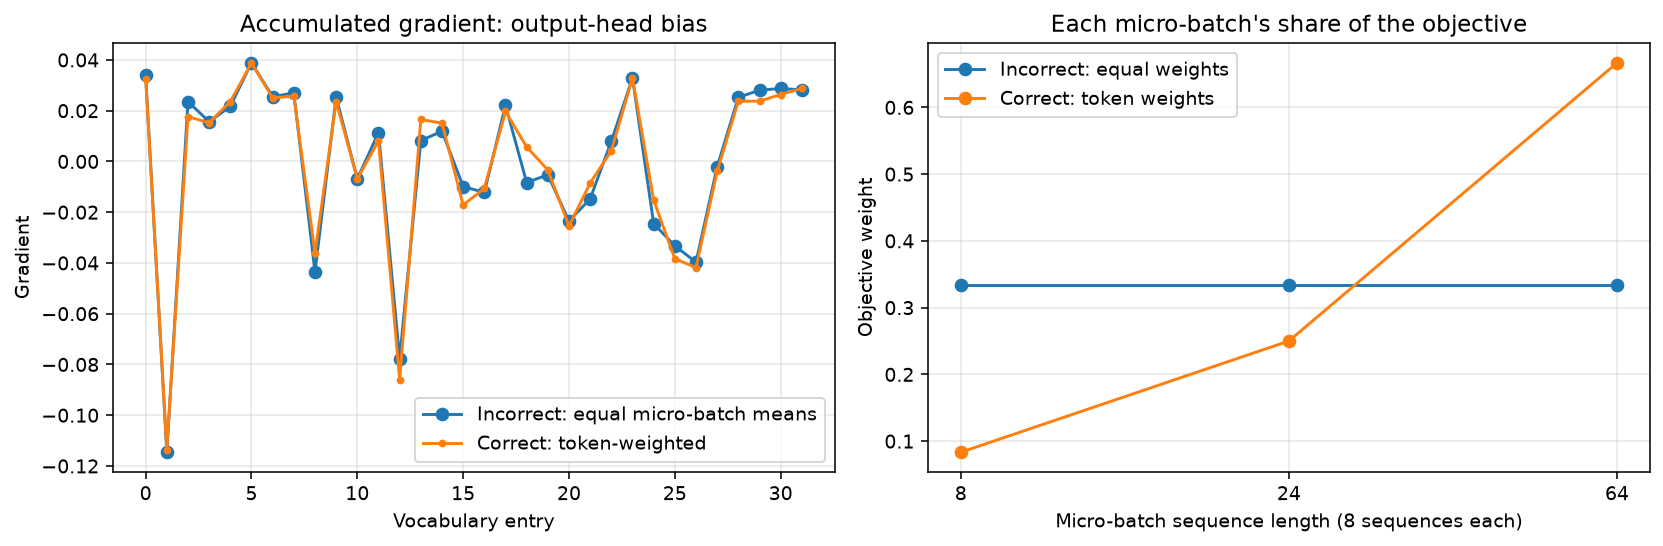

In [6]:
import matplotlib.pyplot as plt

model_was_training = model.training
model.eval()
parameters = tuple(model.parameters())
microbatch_lengths = (8, 24, 64)
microbatch_size = 8
wrong_gradients = [torch.zeros_like(parameter) for parameter in parameters]
weighted_gradient_sums = [torch.zeros_like(parameter) for parameter in parameters]
microbatch_mean_losses = []
microbatch_token_counts = []

for microbatch_index, sequence_length in enumerate(microbatch_lengths):
    starts = (
        torch.arange(microbatch_size, device=device) * (sequence_length + 1)
        + microbatch_index * microbatch_size * (block_size + 1)
    )
    offsets = torch.arange(sequence_length, device=device)
    micro_x = train_data[starts[:, None] + offsets]
    micro_y = train_data[starts[:, None] + offsets + 1]
    micro_logits, _ = model(micro_x)
    summed_token_loss = F.cross_entropy(
        micro_logits.reshape(-1, vocab_size),
        micro_y.reshape(-1),
        reduction="sum",
    )
    token_count = micro_y.numel()
    gradients_of_sum = torch.autograd.grad(summed_token_loss, parameters)
    microbatch_mean_losses.append(summed_token_loss.item() / token_count)
    microbatch_token_counts.append(token_count)
    for parameter_index, gradient_of_sum in enumerate(gradients_of_sum):
        weighted_gradient_sums[parameter_index] += gradient_of_sum
        wrong_gradients[parameter_index] += gradient_of_sum / (
            token_count * len(microbatch_lengths)
        )

total_tokens = sum(microbatch_token_counts)
correct_loss = sum(
    loss * count
    for loss, count in zip(microbatch_mean_losses, microbatch_token_counts)
) / total_tokens
incorrect_loss = sum(microbatch_mean_losses) / len(microbatch_mean_losses)
correct_gradients = [gradient / total_tokens for gradient in weighted_gradient_sums]
wrong_gradient_norm = torch.sqrt(sum(gradient.square().sum() for gradient in wrong_gradients))
correct_gradient_norm = torch.sqrt(sum(gradient.square().sum() for gradient in correct_gradients))
gradient_difference = torch.sqrt(
    sum((wrong - correct).square().sum() for wrong, correct in zip(wrong_gradients, correct_gradients))
)
relative_gradient_difference = gradient_difference / correct_gradient_norm
correct_token_shares = [count / total_tokens for count in microbatch_token_counts]
incorrect_token_shares = [1 / len(microbatch_lengths)] * len(microbatch_lengths)

print(f"micro-batch token counts: {microbatch_token_counts}")
print(f"per-micro-batch mean losses: {[round(value, 6) for value in microbatch_mean_losses]}")
print(f"incorrect equal-micro-batch mean loss: {incorrect_loss:.6f}")
print(f"correct token-weighted mean loss:     {correct_loss:.6f}")
print(f"incorrect gradient norm: {wrong_gradient_norm.item():.6f}")
print(f"correct gradient norm:   {correct_gradient_norm.item():.6f}")
print(f"relative gradient difference: {relative_gradient_difference.item():.2%}")
print(f"equal-micro-batch weights: {[f'{share:.1%}' for share in incorrect_token_shares]}")
print(f"correct token weights:    {[f'{share:.1%}' for share in correct_token_shares]}")

wrong_head_bias = wrong_gradients[-1].detach().cpu().numpy()
correct_head_bias = correct_gradients[-1].detach().cpu().numpy()
microbatch_positions = range(1, len(microbatch_lengths) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(wrong_head_bias, marker="o", label="Incorrect: equal micro-batch means")
axes[0].plot(correct_head_bias, marker=".", label="Correct: token-weighted")
axes[0].set(title="Accumulated gradient: output-head bias", xlabel="Vocabulary entry", ylabel="Gradient")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].plot(microbatch_positions, incorrect_token_shares, marker="o", label="Incorrect: equal weights")
axes[1].plot(microbatch_positions, correct_token_shares, marker="o", label="Correct: token weights")
axes[1].set(
    title="Each micro-batch's share of the objective",
    xlabel="Micro-batch sequence length (8 sequences each)",
    ylabel="Objective weight",
    xticks=list(microbatch_positions),
    xticklabels=[str(length) for length in microbatch_lengths],
)
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
plt.show()
model.train(model_was_training)
fig

The incorrect mean assigns one third of the objective to each micro-batch, so each token in the 8-token sequences gets eight times the weight of a token in the 64-token sequences. Correct weighting gives the three batches `8.3%`, `25.0%`, and `66.7%` of the total token weight. As a result, both the reported loss and the accumulated gradient change; the gradient difference here is specific to this fixed model initialization and these sampled spans.

## Baseline training loop

This loop uses AdamW and cross-entropy over every next-character target in each batch. It records the global gradient norm and batch loss at every update, plus loss on one fixed probe batch after each update. Evaluation also reports means across multiple randomly sampled batches. The settings are intentionally modest; later sections treat these as measurements of this toy setup, not generalization evidence.

In [7]:
import time

@torch.no_grad()
def estimate_loss(eval_batches=10):
    model.eval()
    estimates = {}
    for split in ("train", "validation"):
        losses = []
        for _ in range(eval_batches):
            x, y = get_batch("train" if split == "train" else "validation")
            _, batch_loss = model(x, y)
            losses.append(batch_loss.item())
        estimates[split] = sum(losses) / len(losses)
    model.train()
    return estimates


optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
steps = 500
history = {"step": [], "train_loss": [], "validation_loss": []}
step_gradient_norms = []
step_losses = []
fixed_probe_losses = []
step_time_seconds = []
probe_x, probe_y = xb.clone(), yb.clone()
model.eval()
with torch.no_grad():
    initial_fixed_probe_loss = model(probe_x, probe_y)[1].item()
model.train()

for step in range(steps + 1):
    if step % 50 == 0:
        estimate = estimate_loss()
        history["step"].append(step)
        history["train_loss"].append(estimate["train"])
        history["validation_loss"].append(estimate["validation"])
        print(
            f"step {step:3d} | train loss {estimate['train']:.4f} "
            f"| validation loss {estimate['validation']:.4f}"
        )
        if step and len(step_gradient_norms) >= 50:
            recent_norm = sum(step_gradient_norms[-50:]) / 50
            print(f"           mean gradient norm (last 50 updates): {recent_norm:.4f}")
    if step == steps:
        break
    xb, yb = get_batch("train")
    update_started = time.perf_counter()
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    gradient_norm = torch.sqrt(
        sum(parameter.grad.detach().square().sum() for parameter in model.parameters()
            if parameter.grad is not None)
    )
    optimizer.step()
    if device.type == "mps":
        torch.mps.synchronize()
    step_time_seconds.append(time.perf_counter() - update_started)
    step_gradient_norms.append(gradient_norm.item())
    step_losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        fixed_probe_losses.append(model(probe_x, probe_y)[1].item())
    model.train()

mean_update_seconds = sum(step_time_seconds) / len(step_time_seconds)
print(f"mean forward/backward/update time: {mean_update_seconds * 1000:.3f} ms")
print(f"recorded gradient norms: {len(step_gradient_norms)} (one per optimizer update)")

step   0 | train loss 3.5725 | validation loss 3.5701
step  50 | train loss 2.0510 | validation loss 2.0703
           mean gradient norm (last 50 updates): 0.3297
step 100 | train loss 1.3710 | validation loss 1.3791
           mean gradient norm (last 50 updates): 0.4328
step 150 | train loss 0.5943 | validation loss 0.5944
           mean gradient norm (last 50 updates): 0.7070
step 200 | train loss 0.2504 | validation loss 0.2558
           mean gradient norm (last 50 updates): 0.7273
step 250 | train loss 0.1521 | validation loss 0.1447
           mean gradient norm (last 50 updates): 0.4948
step 300 | train loss 0.1060 | validation loss 0.1031
           mean gradient norm (last 50 updates): 0.3555
step 350 | train loss 0.0918 | validation loss 0.0928
           mean gradient norm (last 50 updates): 0.2842
step 400 | train loss 0.0859 | validation loss 0.0861
           mean gradient norm (last 50 updates): 0.2729
step 450 | train loss 0.0817 | validation loss 0.0810
           m

## Gradient norms and loss dynamics

The training loop records the global L2 gradient norm for every optimizer update. The fixed probe batch is held constant and evaluated after each update, separating changes in model progress from the noise of a newly sampled training batch. A 10-step moving average makes the trend easier to see; the marked lag candidate is descriptive evidence from this run, not proof that a gradient-norm change caused a later loss change.

updates logged: 500
global gradient norm: 0.782626 -> 0.274952
fixed-probe loss: 3.560616 -> 0.076796
10-step mean gradient norm changed by 3.47% at update 212
10-step mean probe loss changed immediately by 0.000003
then changed by 0.009562 over the next 5 updates


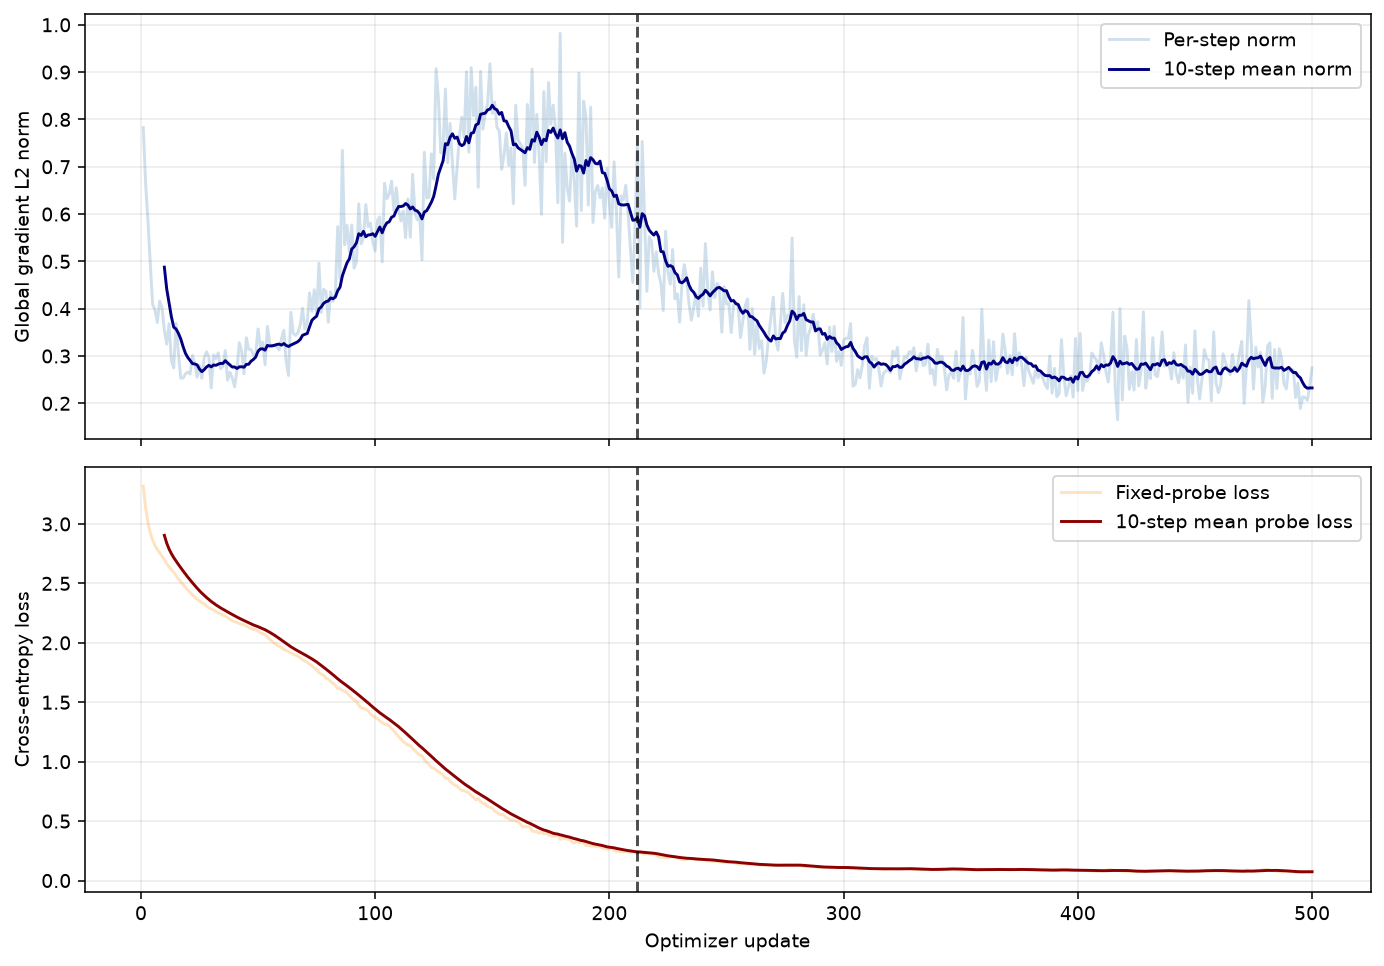

In [8]:
import numpy as np
import matplotlib.pyplot as plt

smoothing_window = 10
gradient_norm_smooth = np.convolve(
    step_gradient_norms, np.ones(smoothing_window) / smoothing_window, mode="valid"
)
probe_loss_smooth = np.convolve(
    fixed_probe_losses, np.ones(smoothing_window) / smoothing_window, mode="valid"
)
lag_candidates = []
for index in range(1, len(gradient_norm_smooth) - 5):
    norm_change = abs(gradient_norm_smooth[index] - gradient_norm_smooth[index - 1])
    relative_norm_change = norm_change / max(gradient_norm_smooth[index - 1], 1e-12)
    immediate_loss_change = abs(probe_loss_smooth[index] - probe_loss_smooth[index - 1])
    next_five_loss_change = abs(probe_loss_smooth[index + 5] - probe_loss_smooth[index])
    if relative_norm_change >= 0.03 and immediate_loss_change < 0.25 * next_five_loss_change:
        score = relative_norm_change * next_five_loss_change / (immediate_loss_change + 1e-12)
        lag_candidates.append((score, index, relative_norm_change, immediate_loss_change, next_five_loss_change))
if not lag_candidates:
    raise RuntimeError("No gradient-before-probe-loss lag met the documented selection criterion")

_, lag_index, relative_norm_change, immediate_loss_change, next_five_loss_change = max(lag_candidates)
lag_step = lag_index + smoothing_window - 1
print(f"updates logged: {len(step_gradient_norms)}")
print(f"global gradient norm: {step_gradient_norms[0]:.6f} -> {step_gradient_norms[-1]:.6f}")
print(f"fixed-probe loss: {initial_fixed_probe_loss:.6f} -> {fixed_probe_losses[-1]:.6f}")
print(f"10-step mean gradient norm changed by {relative_norm_change:.2%} at update {lag_step}")
print(f"10-step mean probe loss changed immediately by {immediate_loss_change:.6f}")
print(f"then changed by {next_five_loss_change:.6f} over the next 5 updates")

steps_axis = np.arange(1, len(step_gradient_norms) + 1)
smooth_steps = np.arange(smoothing_window, len(step_gradient_norms) + 1)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(steps_axis, step_gradient_norms, color="steelblue", alpha=0.25, label="Per-step norm")
axes[0].plot(smooth_steps, gradient_norm_smooth, color="navy", label="10-step mean norm")
axes[0].set_ylabel("Global gradient L2 norm")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(steps_axis, fixed_probe_losses, color="darkorange", alpha=0.25, label="Fixed-probe loss")
axes[1].plot(smooth_steps, probe_loss_smooth, color="darkred", label="10-step mean probe loss")
axes[1].set(xlabel="Optimizer update", ylabel="Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.25)
for axis in axes:
    axis.axvline(lag_step, color="black", linestyle="--", alpha=0.7)
fig.tight_layout()
plt.show()
fig

## Approximate MFU

For this estimate, a dense matrix multiply is counted as two FLOPs per multiply-accumulate. The forward-plus-backward cost of dense weights is approximated as `6 * dense_weight_parameters * tokens`; attention's query-key and weight-value matrix products add approximately `12 * layers * batch * sequence_length^2 * embedding_width` FLOPs per update. This omits embeddings, softmax, normalization, optimizer arithmetic, and other elementwise work, so it is an approximation.

The system identifies an Apple M4 Pro with a 16-core GPU, but neither macOS system information nor this PyTorch MPS setup provides a validated peak FP32 FLOP/s figure. Therefore the notebook reports measured model FLOP/s and an explicitly illustrative MFU using a 4 TFLOP/s assumed peak, alongside sensitivity to other assumed peaks. Under that illustrative assumption, 40% would mean 1.6 TFLOP/s, about 5.7 times the measured rate; the gap is consistent with this tiny model, short sequences, eager Python/MPS dispatch overhead, and non-fused attention. Treat the percentage and gap as a scenario, not a hardware-certified MFU or a fair comparison to a 40% target.

In [9]:
dense_weight_parameters = sum(
    module.weight.numel() for module in model.modules() if isinstance(module, nn.Linear)
)
tokens_per_update = batch_size * block_size
dense_training_flops = 6 * dense_weight_parameters * tokens_per_update
attention_training_flops = (
    12 * len(model.blocks) * batch_size * block_size**2 * model.token_embedding.embedding_dim
)
estimated_flops_per_update = dense_training_flops + attention_training_flops
measured_flops_per_second = estimated_flops_per_update / mean_update_seconds
illustrative_peak_flops = 4e12
illustrative_mfu = measured_flops_per_second / illustrative_peak_flops

print("device: Apple M4 Pro, 16-core GPU via PyTorch MPS")
print(f"linear-layer weight parameters: {dense_weight_parameters:,}")
print(f"tokens per update: {tokens_per_update:,}")
print(f"dense forward+backward estimate: {dense_training_flops / 1e9:.3f} GFLOPs/update")
print(f"attention forward+backward estimate: {attention_training_flops / 1e9:.3f} GFLOPs/update")
print(f"estimated total: {estimated_flops_per_update / 1e9:.3f} GFLOPs/update")
print(f"mean measured update time: {mean_update_seconds * 1000:.3f} ms")
print(f"achieved estimate: {measured_flops_per_second / 1e9:.2f} GFLOP/s")
print(f"illustrative MFU at assumed 4 TFLOP/s peak: {illustrative_mfu:.2%}")
print("sensitivity (assumed peak -> apparent MFU):")
for assumed_peak_tflops in (3, 4, 5):
    print(f"  {assumed_peak_tflops} TFLOP/s -> {measured_flops_per_second / (assumed_peak_tflops * 1e12):.2%}")
print("The 4 TFLOP/s denominator is illustrative, not an Apple-published or measured peak.")

device: Apple M4 Pro, 16-core GPU via PyTorch MPS
linear-layer weight parameters: 100,352
tokens per update: 2,048
dense forward+backward estimate: 1.233 GFLOPs/update
attention forward+backward estimate: 0.201 GFLOPs/update
estimated total: 1.434 GFLOPs/update
mean measured update time: 4.971 ms
achieved estimate: 288.56 GFLOP/s
illustrative MFU at assumed 4 TFLOP/s peak: 7.21%
sensitivity (assumed peak -> apparent MFU):
  3 TFLOP/s -> 9.62%
  4 TFLOP/s -> 7.21%
  5 TFLOP/s -> 5.77%
The 4 TFLOP/s denominator is illustrative, not an Apple-published or measured peak.


## Floating-point encodings of `0.1`

`0.1` has a repeating binary expansion, so none of these finite formats represents it exactly. The code below rounds the same decimal input into IEEE fp32, bf16, and PyTorch's finite-only fp8 E4M3 format and prints the actual bits and decoded values. E4M3 uses one sign bit, four exponent bits (bias 7), and three fraction bits; bf16 retains fp32's exponent width but has only seven fraction bits.

In [10]:
import struct

value = 0.1
fp32_bits = format(int.from_bytes(struct.pack(">f", value), byteorder="big"), "032b")
bf16_value = torch.tensor([value], dtype=torch.float32).to(torch.bfloat16)
bf16_bits = format(int(bf16_value.view(torch.uint16).item()), "016b")
fp8_value = torch.tensor([value], dtype=torch.float32).to(torch.float8_e4m3fn)
fp8_bits = format(int(fp8_value.view(torch.uint8).item()), "08b")

print(f"fp32     sign|exponent|fraction: {fp32_bits[0]}|{fp32_bits[1:9]}|{fp32_bits[9:]} -> {struct.unpack('>f', struct.pack('>f', value))[0]:.12f}")
print(f"bf16     sign|exponent|fraction: {bf16_bits[0]}|{bf16_bits[1:9]}|{bf16_bits[9:]} -> {bf16_value.item():.12f}")
print(f"fp8 E4M3 sign|exponent|fraction: {fp8_bits[0]}|{fp8_bits[1:5]}|{fp8_bits[5:]} -> {fp8_value.item():.12f}")

fp32     sign|exponent|fraction: 0|01111011|10011001100110011001101 -> 0.100000001490
bf16     sign|exponent|fraction: 0|01111011|1001101 -> 0.100097656250
fp8 E4M3 sign|exponent|fraction: 0|0011|101 -> 0.101562500000


Encoding details: fp32 has exponent field `01111011` (123 minus bias 127 gives exponent -4) and a 23-bit fraction beginning `1001100...`, approximating significand 1.6. bf16 keeps the same exponent field but only seven fraction bits (`1001101`), giving significand 1.6015625 and value 0.10009765625. For E4M3, `0011` minus exponent bias 7 gives -4 and fraction `101` gives significand 1.625, so it rounds 0.1 to 0.1015625. None is exact because 0.1 has a repeating binary expansion.

For a practical mixed-precision run, I would choose bf16 activations and matrix multiplies when the accelerator supports them, while keeping optimizer states and sensitive accumulation in fp32. Compared with fp16, bf16 has a much wider exponent range, which helps avoid overflow/underflow; compared with E4M3 it offers more precision and range. E4M3 can be useful for carefully scaled low-precision matrix operations, but I would not use it as the sole training representation for this model.

## Sample

Generation is stochastic and is included as a quick sanity check, not as a quality evaluation.

In [11]:
model.eval()
prompt = torch.tensor([encode("A careful model learns")], dtype=torch.long, device=device)
sample = model.generate(prompt, max_new_tokens=180)
print(decode(sample[0].tolist()))

A careful model learns one character at a time. A usl trains ofure. grad loooop loof merne model le learns oone characte ascks the graddents, and updates each weight.
When the input is a short sequence,
